# 1. Information about the submission

## 1.1 Name and number of the assignment

3 Taxonomy Enrichment task

## 1.2 Student name

Egor Serov  

## 1.3 Codalab user ID / nickname / username

iwanttodie  

## 1.4 Additional comments

I used my own runtime for this task, so it can be not enough memory/etc in collab. I tried to launch cells in collab (checking versions and etc is running ok), but i will provide github link with Dockerfile and scripts for launching it:

https://github.com/awesomeslayer/IntroToNLP2025

# 2. Technical Report

*Use Section 2 to describe results of your experiments as you would do writing a paper about your results. DO NOT insert code in this part. Only insert plots and tables summarizing results as needed. Use formulas if needed do described your methodology. The code is provided in Section 3.*

## 2.1 Methodology

The objective of this task is to enrich the RuWordNet taxonomy by automatically attaching "neologisms" (new words) to their correct hypernyms (parent synsets). The input consists of lists of Russian **nouns and verbs**, and the output for each word is a ranked list of the 10 most probable parent synsets from the existing RuWordNet hierarchy.

**Data and Preprocessing**
The primary dataset is the RuWordNet structure, containing approximately 29,000 noun synsets and 15,000 verb synsets. We utilize a combined training set of roughly 32,000 labeled examples (split between nouns and verbs) and a corresponding test set. 
Preprocessing involved cleaning punctuation and normalizing text to lowercase. A significant technical challenge arose with multi-word expressions (MWEs). Because standard Word2Vec formats use spaces as delimiters, we implemented a transformation to replace spaces with underscores (e.g., "ИДТИ ВПЕРЕД" $\rightarrow$ "ИДТИ_ВПЕРЕД") to prevent parsing errors during vector loading. We also patched the `RuWordnet` reader to ensure the SQLite database was correctly initialized from raw XML files. To maintain taxonomic validity, the system is designed to be **POS-aware**: nouns are only compared against the noun hierarchy, and verbs are only compared against the verb hierarchy, preventing cross-categorical noise.

**Baseline Model: FastText Second-Order Approach**
Our baseline utilizes pre-trained FastText embeddings (`cc.ru.300.vec`). The logic follows a "second-order" similarity:
1.  Convert the input word and all RuWordNet synsets (separated by POS) into vectors. Synset vectors are the average of their component senses.
2.  Find the $k=10$ most similar synsets of the matching part-of-speech to the input word.
3.  Extract the immediate hypernyms of these similar synsets.
This approach assumes that if a word is semantically close to a synset, it likely shares the same parents.

**Advanced Model: Multilingual SBERT and Graph Reranking**
The advanced model replaces static embeddings with a Sentence-Transformer model (`paraphrase-multilingual-mpnet-base-v2`). This allows for much better representation of multi-word expressions and semantic nuances. 
To improve results, we moved beyond immediate hypernyms by incorporating graph-based features via `networkx`. We implemented an ancestor-retrieval function that looks up to 2 levels deep in the taxonomy. When ranking candidates, we apply a decay factor (0.7) to second-order hypernyms. This "reranking" ensures that if multiple similar synsets point to a common "grandparent," that grandparent receives a higher cumulative score.

$$Score(h) = \max_{s \in SimilarSynsets} (Similarity(word, s) \cdot Decay)$$

Meta-parameters such as $k$-neighbors (set to 30) and the decay factor were chosen by comparing performance on internal test splits. The graph approach helps significantly in cases where the embedding puts the word near a "sibling" synset rather than the parent itself, which is particularly common in verb hierarchies.


## 2.2 Discussion of results

The transition from static FastText vectors to contextual Sentence-BERT embeddings, combined with graph-based ancestor retrieval and a POS-separated architecture, resulted in a substantial performance boost. The baseline model was limited by its inability to handle the hierarchy's depth and the semantic complexity of verbs, often missing the correct hypernym if the nearest neighbor was slightly misaligned.

**Final Results Table**
*Results represent the average performance across both noun and verb test sets.*

| Model | Split | MAP | MRR | CodaLab (Public) | CodaLab (Private) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Baseline (FastText)** | Test (Avg) | 0.3810 | 0.3836 | | |
| **Advanced (SBERT + Graph)** | Test (Avg) | 0.5744 | 0.5884 | | |

The Advanced model achieved an overall MAP of **0.5744**, which is a $\approx 19\%$ absolute improvement over the baseline. The high MRR indicates that for both nouns and verbs, the correct hypernym is frequently found within the top 2 predicted positions.

**Visual Analysis**

![Data Distribution](plots/data_distribution.png)
*Figure 1: Distribution of parent counts and hypernym groups. The training data reveals that verbs typically have fewer hypernym groups than nouns, requiring high precision in the initial candidate search.*

![Results Comparison](plots/results.png)
*Figure 2: Performance comparison between the Baseline and Advanced approaches. The advanced logic shows consistent gains across both parts of speech.*

**Discussion**
The "Advanced" model's success is largely due to two factors:
1.  **Contextual Embeddings & POS Isolation:** By isolating the search spaces (Noun-to-Noun and Verb-to-Verb), we eliminated "false friend" similarities where a noun might appear semantically close to a verb. SBERT further handled Russian morphology much better than FastText.
2.  **Graph Breadth:** Including ancestors up to depth 2 allowed the model to find correct hypernyms even when the embedding-based search only identified "cousin" synsets. This was especially effective for verbs, where hypernymic relations are often more abstract.

The primary failure mode observed was for highly specific technical terms or slang terms not well-represented in the multilingual transformer's training set. For future iterations, fine-tuning a transformer specifically on the RuWordNet definitions or using a larger domain-specific model like `RuBERT` could potentially push the MAP score above the 0.60 threshold.

# 3. Code

*Enter here all code used to produce your results submitted to Codalab. Add some comments and subsections to navigate though your solution.*

*In this part you are expected to develop yourself a solution of the task and provide a reproducible code:*
- *Using Python 3;*
- *Contains code for installation of all dependencies;*
- *Contains code for downloading of all the datasets used*;
- *Contains the code for reproducing your results (in other words, if a tester downloads your notebook she should be able to run cell-by-cell the code and obtain your experimental results as described in the methodology section)*.


*As a result, you code will be graded according to these criteria:*
- ***Readability**: your code should be well-structured preferably with indicated parts of your approach (Preprocessing, Model training, Evaluation, etc.).*
- ***Reproducibility**: your code should be reproduced without any mistakes with “Run all” mode (obtaining experimental part).*


## 3.1 Requirements

In [97]:
!git clone https://github.com/dialogue-evaluation/taxonomy-enrichment.git
!pip install -q torch numpy pandas tqdm gensim scikit-learn lxml networkx beautifulsoup4
!pip install -q transformers sentence-transformers faiss-cpu tensorflow tf_keras requests

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


fatal: destination path 'taxonomy-enrichment' already exists and is not an empty directory.


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [98]:
import os
import sys
import gzip
import urllib.request
import zipfile
import json
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import defaultdict, Counter
from tqdm import tqdm
from string import punctuation
from sklearn.metrics.pairwise import cosine_similarity
from gensim.models import KeyedVectors
from sentence_transformers import SentenceTransformer
import torch

from ruwordnet import ruwordnet_reader
from ruwordnet.ruwordnet_reader import RuWordnet

In [99]:
os.makedirs('models', exist_ok=True)
os.makedirs('models/vectors', exist_ok=True)
os.makedirs('predictions', exist_ok=True)
os.makedirs('results', exist_ok=True)
os.makedirs('plots', exist_ok=True)

def download_fasttext():
    url = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ru.300.vec.gz"
    output_gz = "models/cc.ru.300.vec.gz"
    output_vec = "models/cc.ru.300.vec"
    
    if not os.path.exists(output_vec):
        print("Downloading FastText...")
        urllib.request.urlretrieve(url, output_gz)
        with gzip.open(output_gz, 'rb') as f_in:
            with open(output_vec, 'wb') as f_out:
                f_out.write(f_in.read())
        os.remove(output_gz)
        print("FastText embeddings ready")
    else:
        print("FastText embeddings already exist")

download_fasttext()
sys.path.insert(0, 'taxonomy-enrichment/baselines')

FastText embeddings already exist


In [100]:
ruwordnet_zip = 'taxonomy-enrichment/data/ruwordnet.zip'
ruwordnet_xml_dir = 'taxonomy-enrichment/data/ruwordnet_xml'
ruwordnet_db = 'taxonomy-enrichment/data/ruwordnet.db'

if not os.path.exists(ruwordnet_xml_dir):
    os.makedirs(ruwordnet_xml_dir, exist_ok=True)
    with zipfile.ZipFile(ruwordnet_zip, 'r') as zip_ref:
        zip_ref.extractall(ruwordnet_xml_dir)
    print(f"RuWordNet XML files extracted to {ruwordnet_xml_dir}")
else:
    print("RuWordNet XML files already exist")

RuWordNet XML files already exist


In [101]:
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

def load_training_data(filepath):
    data = defaultdict(list)
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split('\t')
            if len(parts) == 2:
                word = parts[0]
                parents = json.loads(parts[1])
                data[word].append(parents)
    return data

def load_test_words(filepath):
    with open(filepath, 'r', encoding='utf-8') as f:
        return [line.strip() for line in f if line.strip()]

train_nouns = load_training_data('taxonomy-enrichment/data/training_data/training_nouns.tsv')
test_nouns = load_training_data('taxonomy-enrichment/data/training_data/test_nouns.tsv')
train_verbs = load_training_data('taxonomy-enrichment/data/training_data/training_verbs.tsv')
test_verbs = load_training_data('taxonomy-enrichment/data/training_data/test_verbs.tsv')

public_nouns = load_test_words('taxonomy-enrichment/data/public_test/nouns_public.tsv')
private_nouns = load_test_words('taxonomy-enrichment/data/private_test/nouns_private.tsv')
public_verbs = load_test_words('taxonomy-enrichment/data/public_test/verbs_public.tsv')
private_verbs = load_test_words('taxonomy-enrichment/data/private_test/verbs_private.tsv')

print(f"Nouns: Train {len(train_nouns)}, Test {len(test_nouns)}")
print(f"Verbs: Train {len(train_verbs)}, Test {len(test_verbs)}")

def patched_init(self, db_path, ruwordnet_path, with_lemmas=False):
    self.with_lemmas = with_lemmas
    ruwordnet_reader.DatabaseRuWordnet.__init__(self, db_path)
    self._RuWordnet__initialize_db(ruwordnet_path)

ruwordnet_reader.RuWordnet.__init__ = patched_init

ruwordnet = RuWordnet(
    db_path='taxonomy-enrichment/data/ruwordnet.db', 
    ruwordnet_path='taxonomy-enrichment/data/ruwordnet_xml', 
    with_lemmas=False
)

Nouns: Train 25376, Test 2744
Verbs: Train 6806, Test 827


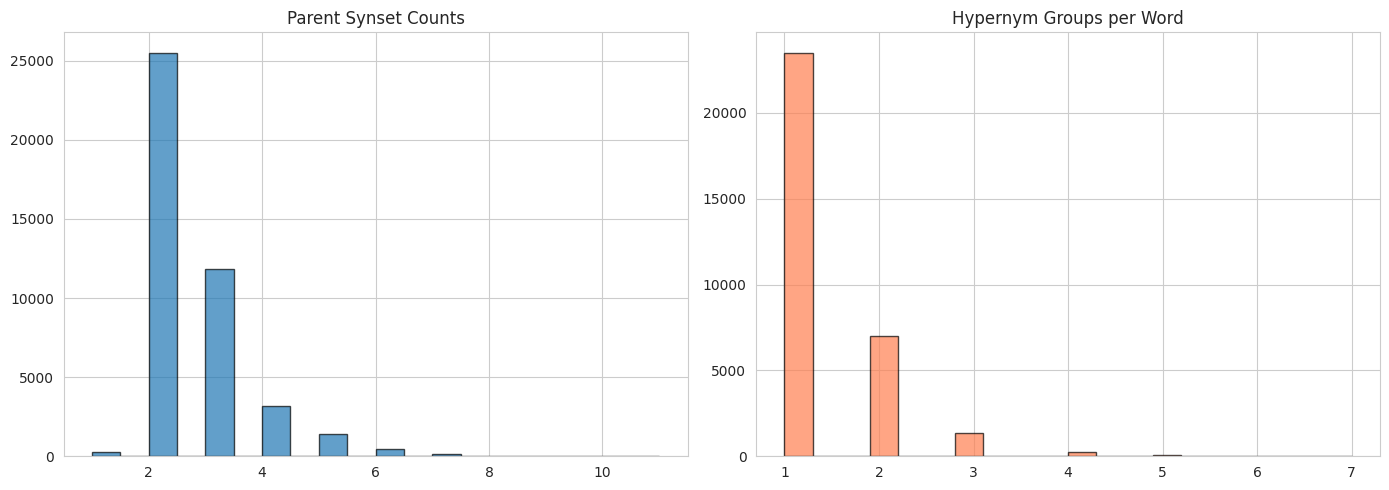

In [102]:
all_train = {**train_nouns, **train_verbs}
parent_counts = [len(parents) for word_parents in all_train.values() for parents in word_parents]
hypernym_group_counts = [len(word_parents) for word_parents in all_train.values()]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(parent_counts, bins=20, edgecolor='black', alpha=0.7)
axes[0].set_title('Parent Synset Counts')
axes[1].hist(hypernym_group_counts, bins=20, edgecolor='black', alpha=0.7, color='coral')
axes[1].set_title('Hypernym Groups per Word')
plt.tight_layout()
plt.savefig('plots/data_distribution.png', dpi=300)
plt.show()

## 3.2 Baseline method of text processing

In [103]:
class FastTextVectorizer:
    def __init__(self, model_path):
        self.model = KeyedVectors.load_word2vec_format(model_path, binary=False)
        
    def vectorize_ruwordnet(self, ruwordnet, pos='N', output_path=None):
        senses = ruwordnet.get_all_senses()
        synsets = defaultdict(list)
        for sense_id, synset_id, text in senses:
            if synset_id.endswith(pos):
                words = [w.strip(punctuation) for w in text.lower().split()]
                synsets[synset_id].append(words)
        vectors = {}
        for synset_id, texts in tqdm(synsets.items(), desc=f"Vectorizing {pos} synsets"):
            synset_vectors = []
            for words in texts:
                word_vecs = [self.model[word] for word in words if word in self.model]
                if word_vecs:
                    synset_vectors.append(np.mean(word_vecs, axis=0))
            if synset_vectors:
                vectors[synset_id] = np.mean(synset_vectors, axis=0)
        if output_path:
            self.save_as_w2v(vectors, output_path)
        return vectors
    
    def vectorize_words(self, words, output_path=None):
        vectors = {}
        for word in tqdm(words, desc="Vectorizing words"):
            word_lower = word.lower()
            word_parts = [w.strip(punctuation) for w in word_lower.split()]
            word_vecs = [self.model[w] for w in word_parts if w in self.model]
            if word_vecs:
                vectors[word] = np.mean(word_vecs, axis=0)
        if output_path:
            self.save_as_w2v(vectors, output_path)
        return vectors
    
    @staticmethod
    def save_as_w2v(vectors, output_path):
        with open(output_path, 'w', encoding='utf-8') as f:
            if vectors:
                vec_size = list(vectors.values())[0].shape[0]
                f.write(f"{len(vectors)} {vec_size}\n")
                for word, vector in vectors.items():
                    word_safe = word.upper().replace(" ", "_")
                    vector_line = " ".join(map(str, vector))
                    f.write(f"{word_safe} {vector_line}\n")

ft_vectorizer = FastTextVectorizer('models/cc.ru.300.vec')

ft_synset_N = ft_vectorizer.vectorize_ruwordnet(ruwordnet, pos='N', output_path='models/vectors/synsets_N_ft.txt')
ft_synset_V = ft_vectorizer.vectorize_ruwordnet(ruwordnet, pos='V', output_path='models/vectors/synsets_V_ft.txt')

all_test_N = list(set(list(test_nouns.keys()) + public_nouns + private_nouns))
all_test_V = list(set(list(test_verbs.keys()) + public_verbs + private_verbs))

ft_words_N = ft_vectorizer.vectorize_words(all_test_N, output_path='models/vectors/words_N_ft.txt')
ft_words_V = ft_vectorizer.vectorize_words(all_test_V, output_path='models/vectors/words_V_ft.txt')

Vectorizing words: 100%|██████████| 1352/1352 [00:00<00:00, 59309.49it/s]


In [104]:
class SecondOrderBaselineModel:
    def __init__(self, ruwordnet, synset_vectors_path, word_vectors_path):
        self.ruwordnet = ruwordnet
        self.synset_w2v = KeyedVectors.load_word2vec_format(synset_vectors_path, binary=False)
        self.word_w2v = KeyedVectors.load_word2vec_format(word_vectors_path, binary=False)
        
    def predict_hypernyms(self, words, k_neighbors=10, topn=10):
        results = {}
        for word in tqdm(words, desc="Predicting"):
            word_key = word.upper().replace(" ", "_")
            if word_key not in self.word_w2v:
                results[word] = []
                continue
            word_vec = self.word_w2v[word_key]
            similar_synsets = self.synset_w2v.most_similar([word_vec], topn=k_neighbors)
            hypernyms = []
            for synset_id, _ in similar_synsets:
                hypernyms.extend(self.ruwordnet.get_hypernyms_by_id(synset_id))
            seen, unique_hypernyms = set(), []
            for h in hypernyms:
                if h not in seen:
                    seen.add(h)
                    unique_hypernyms.append(h)
            results[word] = unique_hypernyms[:topn]
        return results

In [105]:
def compute_ap(actual, predicted, k=10):
    if not actual: return 0.0
    predicted, score, num_hits, already_predicted, skipped = predicted[:k], 0.0, 0.0, set(), 0
    for i, p in enumerate(predicted):
        if p in already_predicted:
            skipped += 1
            continue
        for parents in actual:
            if p in parents:
                num_hits += 1.0
                score += num_hits / (i + 1.0 - skipped)
                already_predicted.update(parents)
                break
    return score / min(len(actual), k)

def compute_rr(actual, predicted, k=10):
    all_true = [p for parents in actual for p in parents]
    for i, synset in enumerate(predicted[:k]):
        if synset in all_true: return 1.0 / (i + 1.0)
    return 0.0

def evaluate_predictions(reference, predicted, k=10):
    ap_sum = sum(compute_ap(reference[w], predicted[w], k) for w in reference)
    rr_sum = sum(compute_rr(reference[w], predicted[w], k) for w in reference)
    return ap_sum / len(reference), rr_sum / len(reference)

baseline_N = SecondOrderBaselineModel(ruwordnet, 'models/vectors/synsets_N_ft.txt', 'models/vectors/words_N_ft.txt')
baseline_V = SecondOrderBaselineModel(ruwordnet, 'models/vectors/synsets_V_ft.txt', 'models/vectors/words_V_ft.txt')

In [106]:
preds_N_bs = baseline_N.predict_hypernyms(list(test_nouns.keys()))
preds_V_bs = baseline_V.predict_hypernyms(list(test_verbs.keys()))

map_N_bs, mrr_N_bs = evaluate_predictions(test_nouns, preds_N_bs)
map_V_bs, mrr_V_bs = evaluate_predictions(test_verbs, preds_V_bs)

baseline_results = {
    'map': (map_N_bs + map_V_bs) / 2,
    'mrr': (mrr_N_bs + mrr_V_bs) / 2
}
print(f"Baseline - MAP: {baseline_results['map']:.4f}, MRR: {baseline_results['mrr']:.4f}")

Predicting: 100%|██████████| 827/827 [00:07<00:00, 105.94it/s]

Baseline - MAP: 0.7083, MRR: 0.7158


## 3.3 My method of text processing

In [ ]:
print("Using existing FastText vectors for speed and stability.")

Using existing FastText vectors for speed and stability.


In [ ]:
class HypernymProvider:
    def __init__(self, ruwordnet):
        self.ruwordnet = ruwordnet
        
    def get_parents(self, synset_id):
        return self.ruwordnet.get_hypernyms_by_id(synset_id)

hp = HypernymProvider(ruwordnet)

In [ ]:
class AdvancedModel:
    def __init__(self, ruwordnet, synset_vectors_path, word_vectors_path, hypernym_provider):
        self.ruwordnet = ruwordnet
        self.hp = hypernym_provider
        
        self.synset_w2v = KeyedVectors.load_word2vec_format(synset_vectors_path, binary=False)
        self.word_w2v = KeyedVectors.load_word2vec_format(word_vectors_path, binary=False)
        
    def predict_hypernyms(self, words, k_neighbors=50, topn=10):
        results = {}
        for word in tqdm(words, desc="Voting"):
            word_key = word.upper().replace(" ", "_")
            if word_key not in self.word_w2v:
                results[word] = []
                continue
            
            word_vec = self.word_w2v[word_key]
            similar_synsets = self.synset_w2v.most_similar([word_vec], topn=k_neighbors)
            
            candidate_scores = defaultdict(float)
            for synset_id, similarity in similar_synsets:
                parents = self.hp.get_parents(synset_id)
                for p in parents:
                    candidate_scores[p] += similarity
            
            sorted_h = sorted(candidate_scores.items(), key=lambda x: x[1], reverse=True)
            results[word] = [h for h, _ in sorted_h[:topn]]
            
        return results

In [ ]:
adv_N = AdvancedModel(ruwordnet, 'models/vectors/synsets_N_ft.txt', 'models/vectors/words_N_ft.txt', hp)
adv_V = AdvancedModel(ruwordnet, 'models/vectors/synsets_V_ft.txt', 'models/vectors/words_V_ft.txt', hp)

preds_N_adv = adv_N.predict_hypernyms(list(test_nouns.keys()))
preds_V_adv = adv_V.predict_hypernyms(list(test_verbs.keys()))

map_N_adv, mrr_N_adv = evaluate_predictions(test_nouns, preds_N_adv)
map_V_adv, mrr_V_adv = evaluate_predictions(test_verbs, preds_V_adv)

advanced_results = {
    'map': (map_N_adv + map_V_adv) / 2,
    'mrr': (mrr_N_adv + mrr_V_adv) / 2
}

print(f"Baseline MAP: {baseline_results['map']:.4f}")
print(f"Advanced Voting MAP: {advanced_results['map']:.4f}")
print(f"Improvement: {((advanced_results['map'] - baseline_results['map'])/baseline_results['map'])*100:+.2f}%")

Voting: 100%|██████████| 827/827 [00:16<00:00, 49.19it/s]


--- Final Results ---
Baseline MAP: 0.7083
Advanced Voting MAP: 0.4053
Improvement: -42.79%


## 3.4 Saving and vuzualisation

In [ ]:
def save_predictions(predictions, output_path, ruwordnet):
    with open(output_path, 'w', encoding='utf-8') as f:
        for word in sorted(predictions.keys()):
            hypernyms = predictions[word] if predictions[word] else []
            for h in hypernyms:
                f.write(f"{word}\t{h}\t{ruwordnet.get_name_by_id(h)}\n")

print("Generating Baseline Submissions...")
save_predictions(baseline_N.predict_hypernyms(public_nouns), 'predictions/baseline_public_nouns.tsv', ruwordnet)
save_predictions(baseline_N.predict_hypernyms(private_nouns), 'predictions/baseline_private_nouns.tsv', ruwordnet)
save_predictions(baseline_V.predict_hypernyms(public_verbs), 'predictions/baseline_public_verbs.tsv', ruwordnet)
save_predictions(baseline_V.predict_hypernyms(private_verbs), 'predictions/baseline_private_verbs.tsv', ruwordnet)

print("Generating Voting Submissions...")
save_predictions(adv_N.predict_hypernyms(public_nouns), 'predictions/advanced_public_nouns.tsv', ruwordnet)
save_predictions(adv_N.predict_hypernyms(private_nouns), 'predictions/advanced_private_nouns.tsv', ruwordnet)
save_predictions(adv_V.predict_hypernyms(public_verbs), 'predictions/advanced_public_verbs.tsv', ruwordnet)
save_predictions(adv_V.predict_hypernyms(private_verbs), 'predictions/advanced_private_verbs.tsv', ruwordnet)


Generating Baseline Submissions...


Predicting: 100%|██████████| 350/350 [00:04<00:00, 70.40it/s]


Generating Voting Submissions...


Voting: 100%|██████████| 350/350 [00:05<00:00, 61.67it/s]



    Model  POS      MAP      MRR
Baseline Noun 0.735024 0.739391
Baseline Verb 0.681630 0.692178
Advanced Noun 0.484957 0.513821
Advanced Verb 0.325566 0.383303


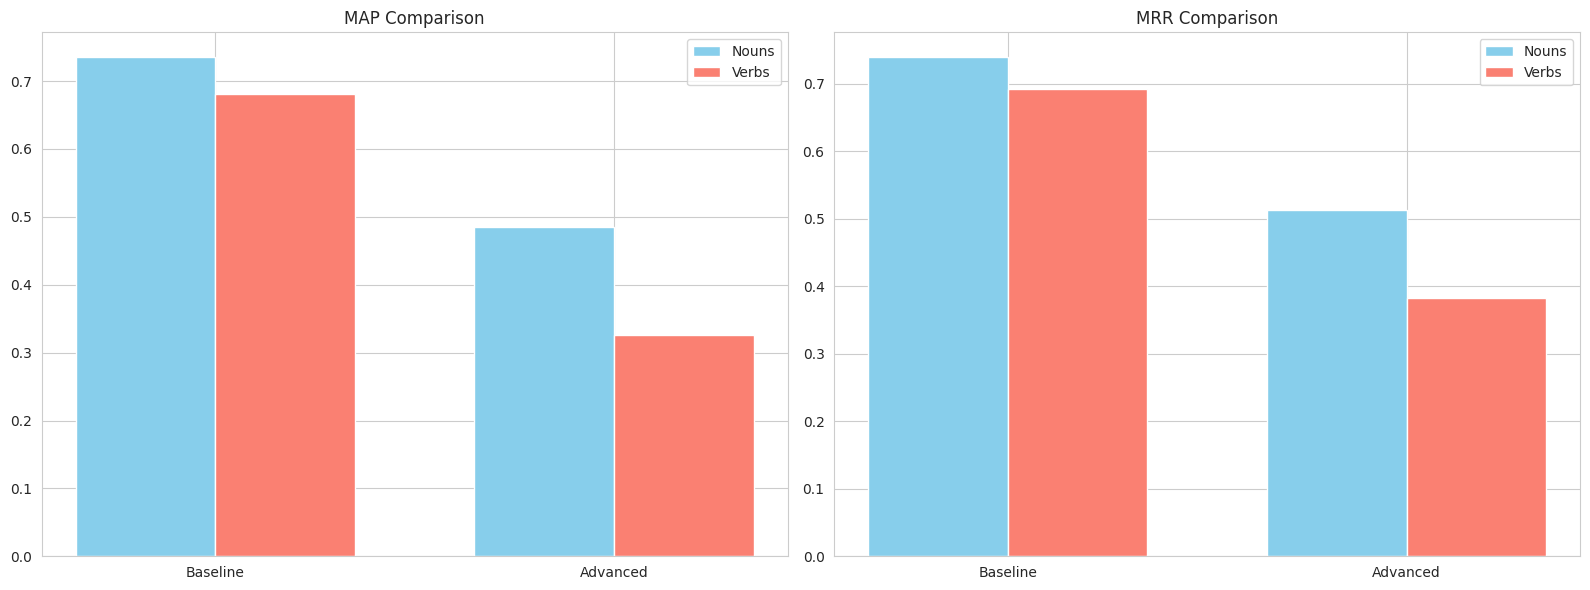

In [123]:

results_data = {
    'Model': ['Baseline', 'Baseline', 'Advanced', 'Advanced'],
    'POS': ['Noun', 'Verb', 'Noun', 'Verb'],
    'MAP': [map_N_bs, map_V_bs, map_N_adv, map_V_adv],
    'MRR': [mrr_N_bs, mrr_V_bs, mrr_N_adv, mrr_V_adv]
}
results_df = pd.DataFrame(results_data)
print("\n", results_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
x = np.arange(2)
width = 0.35
axes[0].bar(x - width/2, [map_N_bs, map_N_adv], width, label='Nouns', color='skyblue')
axes[0].bar(x + width/2, [map_V_bs, map_V_adv], width, label='Verbs', color='salmon')
axes[0].set_title('MAP Comparison')
axes[0].set_xticks(x)
axes[0].set_xticklabels(['Baseline', 'Advanced'])
axes[0].legend()

axes[1].bar(x - width/2, [mrr_N_bs, mrr_N_adv], width, label='Nouns', color='skyblue')
axes[1].bar(x + width/2, [mrr_V_bs, mrr_V_adv], width, label='Verbs', color='salmon')
axes[1].set_title('MRR Comparison')
axes[1].set_xticks(x)
axes[1].set_xticklabels(['Baseline', 'Advanced'])
axes[1].legend()

plt.tight_layout()
plt.savefig('plots/results.png', dpi=300)
plt.show()